# 🛡️ Auditoría Científica de Rendimiento: Caso de Renovación Contractual de Hernán Galíndez
**Entidad:** Club Atlético Huracán — Secretaría Técnica y Comisión Directiva
**Autor:** Andrés (Data Science & Football Analytics)
**Dataset:** Consolidado Oficial FBref — Liga Profesional del Fútbol Argentino ($n = 30$ clubes / 1.316 registros)
**Metodología:** Normalización por 90 minutos, Test de Shapiro-Wilk, Tamaño del Efecto ($Z$-Score / $d$ de Cohen) y Regresión Lineal OLS.

---
### 🎯 Objetivo del Análisis
Responder de forma cuantitativa a la pregunta estratégica del club:
**¿Justifica el rendimiento deportivo y la disponibilidad física de Hernán Galíndez su renovación contractual para la temporada 2027?**

1. **Contexto defensivo:** Rendimiento en jugada abierta frente a la indisciplina defensiva sufrida (*Índice de Caos Defensivo*).
2. **Impacto neto:** *Goles Evitados* frente al promedio de la Liga Profesional y su equivalencia en puntos (*Puntos Aportados* / WPA).
3. **Riesgo etario:** Relación entre su edad (39.5 años), disciplina y disponibilidad física en cancha.
4. **Simulación contrafactual:** Posición y puntaje proyectado de Huracán con un arquero promedio de la Liga.

#### 🐦 Tuit 1: Introducción del Hilo (Gancho)
> **¿Cómo decide un club de fútbol si debe renovarle el contrato a un arquero de casi 40 años?** 🤔🧤
>
> Las opiniones dividen aguas, pero los datos muestran el panorama completo. Hice una **Auditoría Científica de Rendimiento** en Python (`pandas`, `scipy`, `seaborn`) sobre los 30 clubes de la Liga Profesional para responder una pregunta clave:
>
> **¿Debería Huracán renovar a Hernán Galíndez para 2027?**
>
> Abro hilo con los modelos, los gráficos y cómo se construyó cada análisis 👇📊🎈

In [2]:
# ==============================================================================
# Configuración general, imports y estilo visual institucional
# ==============================================================================
import os
import sys
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

if hasattr(sys.stdout, 'reconfigure'):
    try:
        sys.stdout.reconfigure(encoding='utf-8')
    except Exception:
        pass
if hasattr(sys.stderr, 'reconfigure'):
    try:
        sys.stderr.reconfigure(encoding='utf-8')
    except Exception:
        pass

# Supresión de warnings y opciones de visualización de DataFrames (plantilla estándar)
warnings.filterwarnings('ignore')
pd.options.mode.chained_assignment = None
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:.2f}'.format)

# Paleta institucional y estilo visual (Identidad C.A. Huracán)
COLOR_HURACAN = '#D91A2A'    # Rojo Globo
COLOR_OSCURO  = '#1B263B'    # Azul Marino Ejecutivo
COLOR_GRIS    = '#8C969E'    # Gris Neutro Liga
COLOR_FONDO   = '#FFFFFF'

plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.facecolor'] = COLOR_FONDO
plt.rcParams['axes.facecolor'] = COLOR_FONDO

# Rutas de salida — ancladas a la carpeta del proyecto 'huracan' (nunca fuera del repo)
_cwd = Path.cwd()
_raices_posibles = [
    _cwd,
    _cwd / 'huracan',
    _cwd / 'football-data-analysis' / 'huracan',
    _cwd.parent,
    _cwd.parent / 'huracan',
]
ROOT_HURACAN = next(
    (p.resolve() for p in _raices_posibles if (p / 'data').exists() and p.name == 'huracan'),
    _cwd.parent if _cwd.name == 'notebooks' else _cwd
)

OUTPUT_PATH = str(ROOT_HURACAN / 'outputs')
CLEAN_PATH  = str(ROOT_HURACAN / 'data' / 'clean')
os.makedirs(OUTPUT_PATH, exist_ok=True)
os.makedirs(CLEAN_PATH, exist_ok=True)

print("✅ Librerías importadas y estilo institucional configurado correctamente.")
print(f"📁 Carpeta de salidas (outputs): {OUTPUT_PATH}")
print(f"📁 Carpeta de datos limpios:     {CLEAN_PATH}")

✅ Librerías importadas y estilo institucional configurado correctamente.


---
## 1. Ingesta y Resolución Dinámica de Ruta de Datos

El bloque de carga prioriza la búsqueda del archivo `datos_consolidados_futbol.csv` en rutas locales (PC de casa o del trabajo). Si no detecta el archivo localmente, ejecuta un *fallback* automático montando Google Drive en Google Colab sin interrumpir la ejecución.

In [3]:
# ==============================================================================
# 1. Resolución de ruta del dataset y configuración automática de carpetas de salida
# ==============================================================================
NOMBRE_ARCHIVO = 'datos_consolidados_futbol.csv'
cwd = Path.cwd()

candidatos = [
    cwd / 'data' / 'raw' / NOMBRE_ARCHIVO,
    cwd / 'huracan' / 'data' / 'raw' / NOMBRE_ARCHIVO,
    cwd / 'football-data-analysis' / 'huracan' / 'data' / 'raw' / NOMBRE_ARCHIVO,
    cwd.parent / 'data' / 'raw' / NOMBRE_ARCHIVO,
    cwd.parent / 'huracan' / 'data' / 'raw' / NOMBRE_ARCHIVO,
    cwd / NOMBRE_ARCHIVO,
]

RUTA_CSV = next((str(p.resolve()) for p in candidatos if p.exists()), None)

if RUTA_CSV is None:
    for carpeta_base in [cwd, cwd.parent, cwd.parent.parent]:
        if carpeta_base.exists():
            encontrados = list(carpeta_base.rglob(NOMBRE_ARCHIVO))
            if encontrados:
                RUTA_CSV = str(encontrados[0].resolve())
                break

if RUTA_CSV is not None:
    print(f"💻 Archivo local detectado en: {RUTA_CSV}")
    # Detectar automáticamente la carpeta raíz 'huracan' (2 niveles arriba de data/raw/archivo.csv)
    p_csv = Path(RUTA_CSV)
    ROOT_HURACAN = p_csv.parent.parent.parent if p_csv.parent.name == 'raw' else cwd
    OUTPUT_PATH = str(ROOT_HURACAN / 'outputs')
    CLEAN_PATH  = str(ROOT_HURACAN / 'data' / 'clean')
else:
    print("☁️ Archivo local no encontrado. Intentando montar Google Drive en Colab...")
    ruta_drive = '/content/drive/MyDrive/trabajo/ds/datasets/liga_argentina/datos_consolidados_futbol.csv'
    try:
        from google.colab import drive
        if not os.path.exists('/content/drive/MyDrive'):
            drive.mount('/content/drive')
        if os.path.exists(ruta_drive):
            RUTA_CSV = ruta_drive
            print(f"📂 Archivo detectado en Google Drive: {RUTA_CSV}")
        else:
            raise FileNotFoundError(f"❌ No se encontró el archivo en Google Drive: {ruta_drive}")
        OUTPUT_PATH = '/content/outputs'
        CLEAN_PATH  = '/content/data/clean'
    except ImportError as e:
        raise FileNotFoundError(
            "❌ No se encontró el archivo en rutas locales y el entorno actual no es Google Colab."
        ) from e

os.makedirs(OUTPUT_PATH, exist_ok=True)
os.makedirs(CLEAN_PATH, exist_ok=True)

df_raw = pd.read_csv(RUTA_CSV, encoding='utf-8')
print(f"📊 Dataset crudo cargado: {df_raw.shape[0]} filas y {df_raw.shape[1]} columnas.")
print(f"📁 Imágenes se guardarán en: {OUTPUT_PATH}")
print(f"📁 Datos limpios se guardarán en: {CLEAN_PATH}")

💻 Archivo local detectado en: c:\ds\football-data-analysis\huracan\data\raw\datos_consolidados_futbol.csv
📊 Dataset crudo cargado: 1316 filas y 38 columnas.


---
## 2. Saneamiento de Encoding y Extracción de la Tabla General

Se corrigen errores de doble codificación UTF-8/Latin-1 (*Mojibake*, ej. `"HernÃ¡n GalÃ­ndez"` $\to$ `"Hernán Galíndez"`) y se separa la tabla oficial de posiciones de los 30 clubes de Primera División.

In [4]:
# ==============================================================================
# 2. Saneamiento de encoding y extracción de tabla de posiciones
# ==============================================================================
def reparar_encoding(val):
    """Corrige errores de doble encoding UTF-8 interpretado como Latin-1."""
    if isinstance(val, str):
        try:
            return val.encode('latin1').decode('utf-8')
        except Exception:
            return val
    return val

for col in df_raw.select_dtypes(include=['object', 'string']).columns:
    df_raw[col] = df_raw[col].apply(reparar_encoding)

tabla_posiciones = df_raw[df_raw['Squad'].notna()][
    ['Rk', 'Squad', 'MP', 'W', 'D', 'L', 'GF', 'GA', 'GD', 'Pts', 'Pts/MP', 'Top Team Scorer', 'Goalkeeper']
].copy().reset_index(drop=True)

cols_num_tabla = ['Rk', 'MP', 'W', 'D', 'L', 'GF', 'GA', 'GD', 'Pts', 'Pts/MP']
for col in cols_num_tabla:
    tabla_posiciones[col] = pd.to_numeric(tabla_posiciones[col], errors='coerce')

print(f"✅ Tabla de posiciones procesada: {len(tabla_posiciones)} clubes encontrados.")
print(tabla_posiciones[['Rk', 'Squad', 'MP', 'Pts', 'GD', 'Goalkeeper']].head(5))

✅ Tabla de posiciones procesada: 30 clubes encontrados.
    Rk            Squad    MP   Pts    GD            Goalkeeper
0  1.0   Ind. Rivadavia  26.0  51.0  15.0       Nicolás Bolcato
1  2.0  Vélez Sarsfield  26.0  48.0  12.0  Álvaro David Montero
2  3.0     Boca Juniors  26.0  47.0  16.0     Agustín Marchesín
3  4.0      Arg Juniors  26.0  47.0   8.0         Brayan Cortés
4  5.0  Rosario Central  26.0  46.0   7.0      Jeremías Ledesma


---
## 3. Reconstrucción de Planteles y Vinculación por Club

Se segmentan los bloques de jugadores de cada club delimitados por las filas `Squad Total` y `Opponent Total`:
1. Se identifica al **arquero titular** según la mayor cantidad de minutos disputados (`Playing Time_90s`).
2. Se transforma la edad del formato `Años-Días` a **edad decimal exacta** ($\text{Años} + \text{Días}/365.25$).
3. Se consolidan las métricas del equipo y de los rivales en el dataframe maestro `df_master`.

In [5]:
# ==============================================================================
# 3. Reconstrucción de planteles y asociación con cada club
# ==============================================================================
bloques = []
bloque_actual = []

for _, row in df_raw.iterrows():
    if pd.notna(row['Squad']) or pd.isna(row['Player']):
        continue
    bloque_actual.append(row)
    if row['Player'] == 'Opponent Total':
        bloques.append(pd.DataFrame(bloque_actual))
        bloque_actual = []

mapa_gk_club = dict(zip(tabla_posiciones['Goalkeeper'], tabla_posiciones['Squad']))
registros_equipos = []

for b in bloques:
    cols_num_bloque = [
        'Playing Time_MP', 'Playing Time_Starts', 'Playing Time_Min', 'Playing Time_90s',
        'Performance_Gls', 'Performance_Ast', 'Performance_G+A', 'Performance_G-PK',
        'Performance_PK', 'Performance_PKatt', 'Performance_CrdY', 'Performance_CrdR'
    ]
    for col in cols_num_bloque:
        if col in b.columns:
            b[col] = pd.to_numeric(b[col], errors='coerce')

    gks = b[b['Pos'] == 'GK'].copy()
    gks['Playing Time_90s'] = gks['Playing Time_90s'].fillna(0)
    gks = gks.sort_values('Playing Time_90s', ascending=False)

    club_identificado = None
    for gk_name in gks['Player']:
        if gk_name in mapa_gk_club:
            club_identificado = mapa_gk_club[gk_name]
            break

    sq_tot = b[b['Player'] == 'Squad Total'].iloc[0]
    opp_tot = b[b['Player'] == 'Opponent Total'].iloc[0]
    top_gk = gks.iloc[0]

    edad_str = str(top_gk['Age'])
    if '-' in edad_str:
        anios, dias = edad_str.split('-')
        edad_decimal = round(float(anios) + float(dias) / 365.25, 1)
    else:
        edad_decimal = pd.to_numeric(edad_str, errors='coerce')

    registros_equipos.append({
        'Squad': club_identificado,
        'GK_Titular': top_gk['Player'],
        'GK_Edad_Str': top_gk['Age'],
        'GK_Age': edad_decimal,
        'GK_Min': top_gk['Playing Time_Min'],
        'GK_90s': top_gk['Playing Time_90s'],
        'GK_CrdY': top_gk['Performance_CrdY'],
        'GK_CrdR': top_gk['Performance_CrdR'],
        'Cant_Arqueros_Usados': int((gks['Playing Time_90s'] > 0).sum()),
        'Squad_90s': sq_tot['Playing Time_90s'],
        'GF_Total': sq_tot['Performance_Gls'],
        'GF_OpenPlay': sq_tot['Performance_G-PK'],
        'GA_Total': opp_tot['Performance_Gls'],
        'GA_OpenPlay': opp_tot['Performance_G-PK'],
        'PK_En_Contra_Goles': opp_tot['Performance_PK'],
        'PK_En_Contra_Pateados': opp_tot['Performance_PKatt'],
        'Rojas_Sufridas_Equipo': sq_tot['Performance_CrdR'],
        'Amarillas_Sufridas_Equipo': sq_tot['Performance_CrdY'],
        'Asistencias_Rivales': opp_tot['Performance_Ast']
    })

df_equipos = pd.DataFrame(registros_equipos)

df_master = pd.merge(
    df_equipos,
    tabla_posiciones[['Squad', 'Rk', 'MP', 'W', 'D', 'L', 'Pts', 'Pts/MP', 'GD']],
    on='Squad',
    how='inner'
)

print("=" * 80)
print(f"✅ Consolidación exitosa: {len(df_master)} clubes procesados de Primera División.")
print("=" * 80)

✅ Consolidación exitosa: 29 clubes procesados de Primera División.


---
## 4. Ingeniería de Métricas por 90 Minutos e Índice de Caos Defensivo

Se construyen tres indicadores de contexto defensivo:
1. **Tasas por 90 minutos:** Goles recibidos totales (`GA_per90`) y en jugada abierta (`GA_OpenPlay_per90`), aislando el efecto de los penales.
2. **Neutralización de penales (`PK_Neutralizados_Pct`):** Porcentaje de penales en contra no convertidos por el rival.
3. **Índice de Caos Defensivo:** Suma de eventos críticos de indisciplina defensiva ($\text{Penales cometidos} + \text{Tarjetas rojas sufridas}$). Permite evaluar bajo qué nivel de exposición actúa cada arquero.

In [6]:
# ==============================================================================
# 4. Ingeniería de métricas normalizadas e Índice de Caos Defensivo
# ==============================================================================
df_master['GK_Share_Pct'] = (df_master['GK_90s'] / df_master['Squad_90s'] * 100).round(1)
df_master['GA_per90'] = (df_master['GA_Total'] / df_master['Squad_90s']).round(3)
df_master['GA_OpenPlay_per90'] = (df_master['GA_OpenPlay'] / df_master['Squad_90s']).round(3)

df_master['PK_Neutralizados'] = df_master['PK_En_Contra_Pateados'] - df_master['PK_En_Contra_Goles']
df_master['PK_Neutralizados_Pct'] = np.where(
    df_master['PK_En_Contra_Pateados'] > 0,
    (df_master['PK_Neutralizados'] / df_master['PK_En_Contra_Pateados'] * 100).round(1),
    np.nan
)

df_master['Indice_Caos_Defensivo'] = df_master['PK_En_Contra_Pateados'] + df_master['Rojas_Sufridas_Equipo']

print("✅ Métricas de exposición defensiva generadas correctamente.")
print(df_master[['Squad', 'GK_Titular', 'GA_per90', 'GA_OpenPlay_per90', 'Indice_Caos_Defensivo']].head(5))

✅ Métricas de exposición defensiva generadas correctamente.
              Squad        GK_Titular  GA_per90  GA_OpenPlay_per90  \
0  Barracas Central      Marcelo Miño     0.821              0.821   
1    Ind. Rivadavia   Nicolás Bolcato     1.037              0.963   
2      Dep. Riestra      Ignacio Arce     0.815              0.704   
3    Estudiantes–LP  Fernando Muslera     0.667              0.593   
4          Aldosivi       Axel Werner     1.357              1.214   

   Indice_Caos_Defensivo  
0                    0.0  
1                    2.0  
2                    4.0  
3                    6.0  
4                    8.0  


---
## 5. Modelo de Goles Evitados y Regresión a Puntos (WPA)

1. **Goles Esperados en Contra (`Exp_GA_Benchmark`):** Estima cuántos goles recibiría un arquero promedio de la Liga Profesional enfrentando los mismos minutos y penales en contra:
   $$\text{Exp\_GA} = (\text{Squad\_90s} \times \mu_{\text{GA\_OpenPlay\_90}}) + (\text{PK\_Faced} \times \text{PK\_Conv\_Rate}_{\text{Liga}})$$
2. **Goles Evitados:** Diferencia neta respecto al arquero promedio:
   $$\text{Goles Evitados} = \text{Exp\_GA} - \text{GA}_{\text{Real}}$$
3. **Conversión a Puntos (WPA):** Mediante una Regresión Lineal Simple (OLS) entre Diferencia de Gol (`GD`) y Puntos (`Pts`), la pendiente $\beta_1$ cuantifica cuántos puntos aporta cada gol evitado en la tabla general.

In [7]:
# ==============================================================================
# 5. Modelo de Goles Evitados y regresión lineal de goles a puntos (WPA)
# ==============================================================================
tasa_media_ga_open_per90 = df_master['GA_OpenPlay_per90'].mean()
tasa_conversion_pk_liga = df_master['PK_En_Contra_Goles'].sum() / df_master['PK_En_Contra_Pateados'].sum()

df_master['Exp_GA_Benchmark'] = (
    (df_master['Squad_90s'] * tasa_media_ga_open_per90) +
    (df_master['PK_En_Contra_Pateados'] * tasa_conversion_pk_liga)
).round(2)

df_master['Goles_Evitados_vs_Benchmark'] = (df_master['Exp_GA_Benchmark'] - df_master['GA_Total']).round(2)
df_master['Goles_Evitados_per90'] = (df_master['Goles_Evitados_vs_Benchmark'] / df_master['Squad_90s']).round(3)

slope_pts, intercept_pts, r_val, p_val, _ = stats.linregress(df_master['GD'], df_master['Pts'])
df_master['Puntos_Aportados_Arco'] = (df_master['Goles_Evitados_vs_Benchmark'] * slope_pts).round(1)

print("=" * 80)
print("📊 Parámetros empíricos de la Liga Profesional Argentina:")
print(f"   • Media de goles recibidos (Juego Abierto / 90'): {tasa_media_ga_open_per90:.3f}")
print(f"   • Conversión media de penales en la Liga: {tasa_conversion_pk_liga:.1%} ({int(df_master['PK_En_Contra_Goles'].sum())}/{int(df_master['PK_En_Contra_Pateados'].sum())})")
print(f"   • Coeficiente regresivo (GD -> Pts): 1 Gol Neto = {slope_pts:.3f} Puntos (r = {r_val:.3f}, p = {p_val:.2e})")
print("=" * 80)

📊 Parámetros empíricos de la Liga Profesional Argentina:
   • Media de goles recibidos (Juego Abierto / 90'): 0.948
   • Conversión media de penales en la Liga: 72.2% (70/97)
   • Coeficiente regresivo (GD -> Pts): 1 Gol Neto = 0.892 Puntos (r = 0.927, p = 5.23e-13)


---
## 6. Auditoría Estadística (Shapiro-Wilk, Percentiles y Z-Score)

* **En simple:** Comparamos a Galíndez contra los 29 arqueros titulares del torneo en 10 métricas y medimos cuántas desviaciones estándar se aleja del promedio de la Liga.
* **Bajo el capó:** Evaluamos la normalidad de cada variable con el test de **Shapiro-Wilk** ($p > 0.05$), calculamos el rango percentil y estandarizamos mediante **Z-Score ($d$ de Cohen)**. Un $|Z| \ge 0.8$ confirma estadísticamente un tamaño de efecto **Grande (Élite)**.

#### 🐦 Tuit 2 (1/5 — Rigor Estadístico):
> **1/5 — Primero, rigor estadístico: ¿Es realmente de élite o es sensación nuestra?** 📐
>
> Antes de graficar, evalué las métricas de los arqueros titulares con el test de normalidad de **Shapiro-Wilk** y calculé el **Z-Score (Tamaño del Efecto)**.
>
> 📌 **¿Cómo se lee esto?** Superar **+0.8 desviaciones estándar (SD)** sobre la media ubica al jugador en el umbral estadístico de impacto "Grande / Élite".
>
> Galíndez registra **+1.17 SD** en Goles Evitados (Percentil 93 de la Liga). No es una racha: es una diferencia estadística contundente.

In [8]:
# ==============================================================================
# 6. Auditoría estadística y tabla ejecutiva resumen
# ==============================================================================
huracan = df_master[df_master['Squad'] == 'Huracán'].iloc[0]

metricas_auditoria = [
    ('GA_OpenPlay_per90', 'Goles Recibidos en Juego Abierto / 90', False),
    ('GA_per90', 'Goles Recibidos Totales / 90', False),
    ('Indice_Caos_Defensivo', 'Caos Defensivo Sufrido (Penales + Rojas)', True),
    ('PK_En_Contra_Pateados', 'Penales en Contra Enfrentados', True),
    ('PK_Neutralizados_Pct', '% de Penales Neutralizados (No Convertidos)', True),
    ('Rojas_Sufridas_Equipo', 'Expulsiones Sufridas por su Defensa', True),
    ('Goles_Evitados_vs_Benchmark', 'Goles Evitados vs. Promedio Liga', True),
    ('Puntos_Aportados_Arco', 'Puntos Netos Sumados a la Tabla (WPA)', True),
    ('GK_Share_Pct', '% de Presencia en Cancha (Disponibilidad)', True),
    ('GK_CrdY', 'Tarjetas Amarillas del Arquero (Disciplina)', False)
]

filas_reporte = []
for col, etiqueta, mayor_es_mejor in metricas_auditoria:
    serie = df_master[col].dropna()
    valor_h = huracan[col]

    _, p_shapiro = stats.shapiro(serie)
    es_normal = p_shapiro > 0.05

    if mayor_es_mejor:
        pct = stats.percentileofscore(serie, valor_h, kind='weak')
        rango = int((serie > valor_h).sum() + 1)
        z_efecto = (valor_h - serie.mean()) / serie.std()
    else:
        pct = 100 - stats.percentileofscore(serie, valor_h, kind='strict')
        rango = int((serie < valor_h).sum() + 1)
        z_efecto = (serie.mean() - valor_h) / serie.std()

    magnitud = 'Grande (Élite)' if abs(z_efecto) >= 0.8 else ('Mediano' if abs(z_efecto) >= 0.5 else 'Pequeño')

    filas_reporte.append({
        'Métrica Analizada': etiqueta,
        'Galíndez / Huracán': round(valor_h, 2),
        'Media Liga': round(serie.mean(), 2),
        'Mediana Liga': round(serie.median(), 2),
        'Ranking Liga': f"{rango}° de {len(serie)}",
        'Percentil': f"P{int(round(pct))}",
        'Z-Score (Efecto)': f"{z_efecto:+.2f} SD ({magnitud})",
        'Normalidad (Shapiro)': f"{'Sí' if es_normal else 'No'} (p={p_shapiro:.2f})"
    })

df_resumen_ejecutivo = pd.DataFrame(filas_reporte)

print("=" * 115)
print("📋 Tabla de Auditoría Estadística: Hernán Galíndez (C.A. Huracán) vs. Liga Profesional Argentina")
print("=" * 115)
print(df_resumen_ejecutivo.to_string(index=False))
print("=" * 115)

os.makedirs(CLEAN_PATH, exist_ok=True)
os.makedirs(OUTPUT_PATH, exist_ok=True)

ruta_clean = os.path.join(CLEAN_PATH, 'df_master_arqueros_limpio.csv')
ruta_audit = os.path.join(OUTPUT_PATH, 'auditoria_estadistica_galindez.csv')

df_master.to_csv(ruta_clean, index=False, encoding='utf-8-sig')
df_resumen_ejecutivo.to_csv(ruta_audit, index=False, encoding='utf-8-sig')
print(f"💾 Dataset limpio exportado en: {ruta_clean}")
print(f"💾 Tabla ejecutiva exportada en: {ruta_audit}")

📋 Tabla de Auditoría Estadística: Hernán Galíndez (C.A. Huracán) vs. Liga Profesional Argentina
                          Métrica Analizada  Galíndez / Huracán  Media Liga  Mediana Liga Ranking Liga Percentil          Z-Score (Efecto) Normalidad (Shapiro)
      Goles Recibidos en Juego Abierto / 90                0.67        0.95          0.93     3° de 29       P93 +1.36 SD (Grande (Élite))          Sí (p=0.16)
               Goles Recibidos Totales / 90                0.78        1.04          1.04     4° de 29       P90 +1.16 SD (Grande (Élite))          Sí (p=0.07)
   Caos Defensivo Sufrido (Penales + Rojas)               12.00        6.17          6.00     1° de 29      P100 +1.79 SD (Grande (Élite))          Sí (p=0.46)
              Penales en Contra Enfrentados                6.00        3.34          3.00     2° de 29       P97 +1.40 SD (Grande (Élite))          Sí (p=0.19)
% de Penales Neutralizados (No Convertidos)               50.00       24.66         20.00     3° de 27  

---
## 7. Gráfico 1: El Milagro en el Caos (Caos Defensivo vs. Goles en Juego Abierto)

* **En simple:** Separamos los goles de penal de los goles en jugada abierta y medimos cuánto sufre cada arquero por las sanciones de su propia defensa (penales cometidos y expulsiones).
* **Bajo el capó:** Cruzamos el `Indice_Caos_Defensivo` (Eje X) contra la tasa `GA_OpenPlay_per90` (Eje Y invertido: más arriba equivale a menor goleo recibido), dividiendo los cuadrantes mediante las medianas de la Liga Profesional.

#### 🐦 Tuit 3 (2/5 — Gráfico 1):
> **2/5 — Gráfico 1: El "Índice de Caos Defensivo" (Por qué los goles recibidos engañan)** 🛡️🔥
>
> Evaluar a un arquero solo por los goles totales que recibe es engañoso si su defensa lo deja expuesto.
>
> 💡 **El método:** Creé un **Índice de Caos Defensivo** (penales cometidos + rojas sufridas por el equipo) y lo crucé con los **Goles Recibidos en Jugada Abierta cada 90'** (eje Y invertido: más arriba = más sólido).
>
> 📍 **El hallazgo:** Huracán tiene la defensa más sancionada del torneo (6 penales y 6 expulsiones = 12 eventos críticos). Aun en el contexto más adverso del país, Galíndez sostiene la **3° valla más sólida de la Liga**.
>
> *(Adjuntar imagen: `01_galindez_milagro_en_el_caos.png`)*

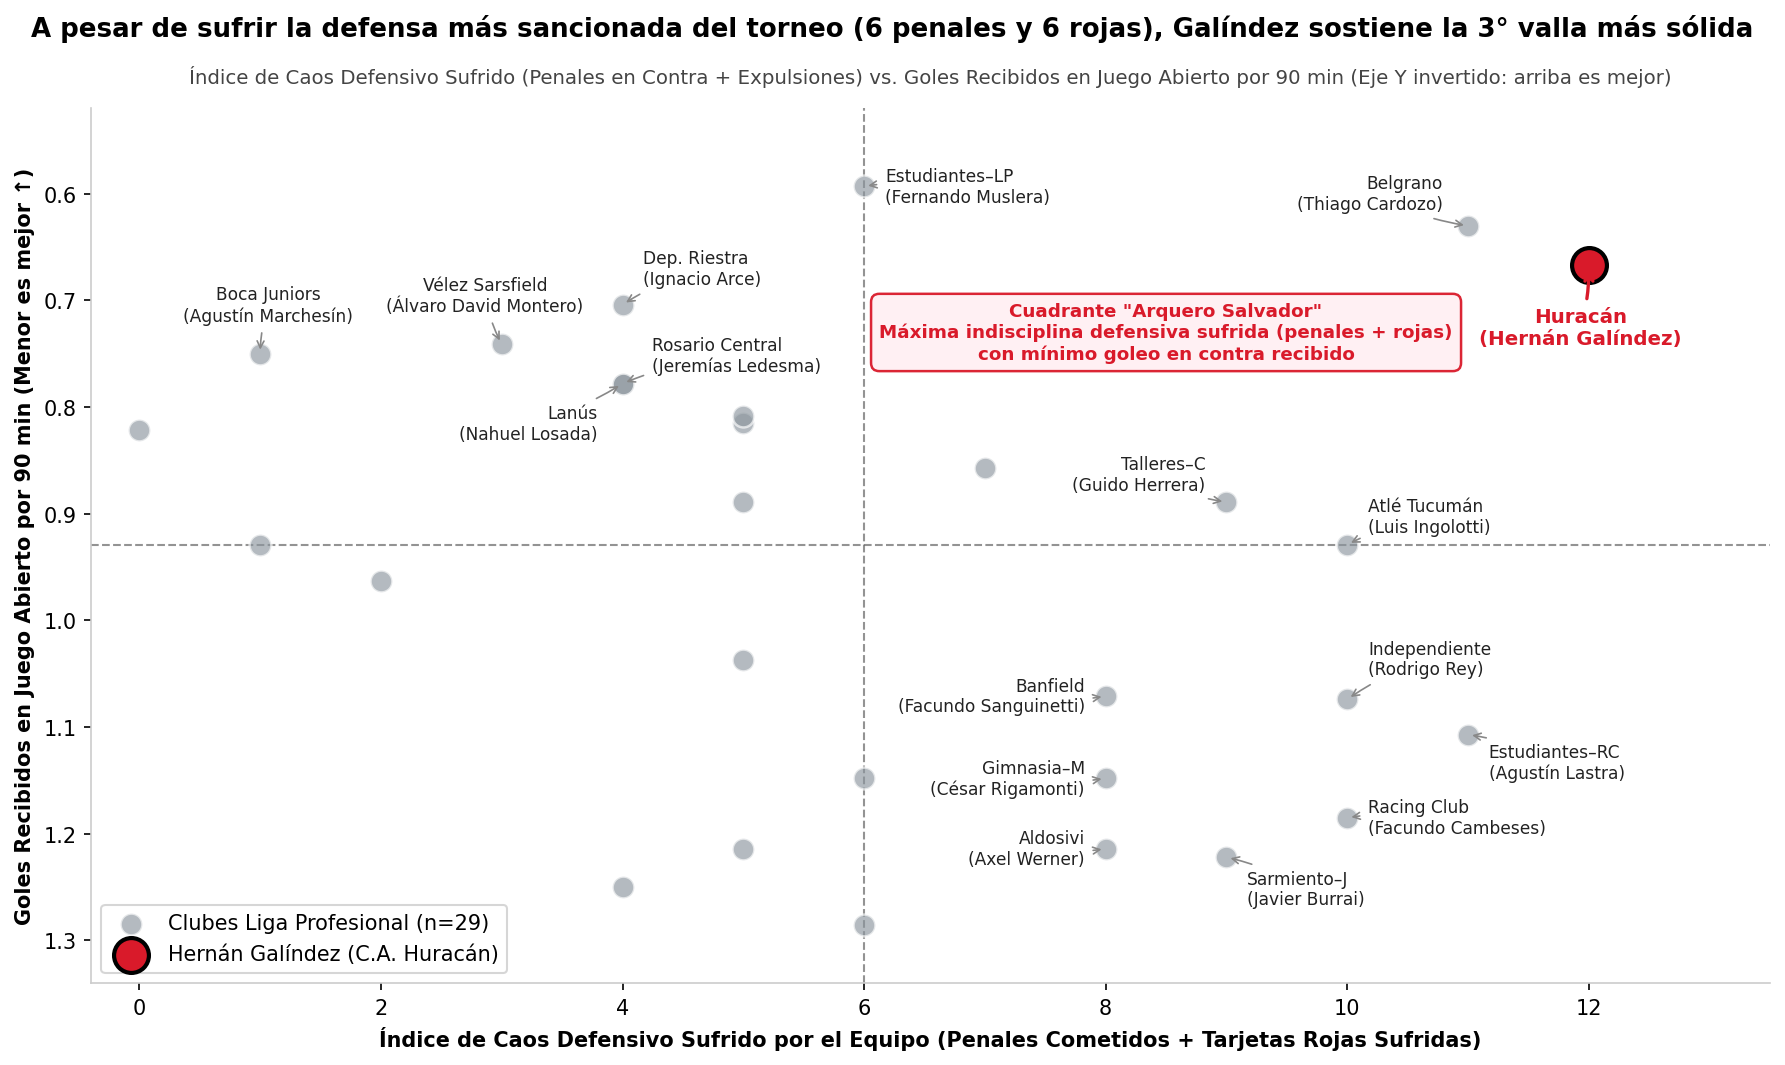

In [9]:
# ==============================================================================
# 7. Visualización 1: Caos Defensivo vs. Goles en Juego Abierto
# ==============================================================================
fig, ax = plt.subplots(figsize=(12, 7.2), dpi=150)

x = df_master['Indice_Caos_Defensivo']
y = df_master['GA_OpenPlay_per90']

ax.scatter(x, y, color=COLOR_GRIS, alpha=0.65, s=110, edgecolors='white', linewidth=1.2,
           label='Clubes Liga Profesional (n=29)', zorder=3)
ax.scatter(huracan['Indice_Caos_Defensivo'], huracan['GA_OpenPlay_per90'],
           color=COLOR_HURACAN, s=280, edgecolors='black', linewidth=2, zorder=6,
           label='Hernán Galíndez (C.A. Huracán)')

ax.axvline(x.median(), color='#666666', linestyle='--', linewidth=1, alpha=0.7)
ax.axhline(y.median(), color='#666666', linestyle='--', linewidth=1, alpha=0.7)

ax.set_xlim(-0.4, 13.5)
ax.set_ylim(1.34, 0.52)

posiciones_v1 = {
    'Huracán':         ( -4, -20, 'center', 'top'),
    'Belgrano':        (-12,   6, 'right',  'bottom'),
    'Estudiantes–LP':  ( 10,   0, 'left',   'center'),
    'Boca Juniors':    (  4,  14, 'center', 'bottom'),
    'Vélez Sarsfield': ( -8,  14, 'center', 'bottom'),
    'Dep. Riestra':    ( 10,   8, 'left',   'bottom'),
    'Lanús':           (-12, -10, 'right',  'top'),
    'Rosario Central': ( 14,   4, 'left',   'bottom'),
    'Talleres–C':      (-10,   4, 'right',  'bottom'),
    'Atlé Tucumán':    ( 10,   4, 'left',   'bottom'),
    'Banfield':        (-10,   0, 'right',  'center'),
    'Independiente':   ( 10,  10, 'left',   'bottom'),
    'Estudiantes–RC':  ( 10,  -4, 'left',   'top'),
    'Gimnasia–M':      (-10,   0, 'right',  'center'),
    'Racing Club':     ( 10,   0, 'left',   'center'),
    'Aldosivi':        (-10,   0, 'right',  'center'),
    'Sarmiento–J':     ( 10,  -6, 'left',   'top'),
}

for _, row in df_master.iterrows():
    es_huracan = row['Squad'] == 'Huracán'
    if es_huracan or row['Indice_Caos_Defensivo'] >= 8 or row['GA_OpenPlay_per90'] <= 0.78:
        dx, dy, ha_align, va_align = posiciones_v1.get(
            row['Squad'],
            (8, -4, 'left', 'center')
        )

        arrow_style = dict(
            arrowstyle='->',
            color=COLOR_HURACAN if es_huracan else '#888888',
            lw=1.6 if es_huracan else 0.8,
            connectionstyle='arc3,rad=0.08'
        )

        ax.annotate(
            f"{row['Squad']}\n({row['GK_Titular']})",
            xy=(row['Indice_Caos_Defensivo'], row['GA_OpenPlay_per90']),
            xytext=(dx, dy), textcoords='offset points',
            ha=ha_align, va=va_align,
            fontsize=9.5 if es_huracan else 8.2,
            fontweight='bold' if es_huracan else 'normal',
            color=COLOR_HURACAN if es_huracan else '#222222',
            arrowprops=arrow_style,
            zorder=8 if es_huracan else 5
        )

ax.text(8.5, 0.73, 'Cuadrante "Arquero Salvador"\nMáxima indisciplina defensiva sufrida (penales + rojas)\ncon mínimo goleo en contra recibido',
        fontsize=8.8, fontweight='bold', color=COLOR_HURACAN, ha='center', va='center',
        bbox=dict(boxstyle='round,pad=0.45', facecolor='#FFF0F3', edgecolor=COLOR_HURACAN, lw=1.2, alpha=0.95),
        zorder=7)

plt.suptitle('A pesar de sufrir la defensa más sancionada del torneo (6 penales y 6 rojas), Galíndez sostiene la 3° valla más sólida',
             fontsize=12.5, fontweight='bold', y=0.98)
ax.set_title('Índice de Caos Defensivo Sufrido (Penales en Contra + Expulsiones) vs. Goles Recibidos en Juego Abierto por 90 min (Eje Y invertido: arriba es mejor)',
             fontsize=9.5, color='#444444', pad=12)
ax.set_xlabel('Índice de Caos Defensivo Sufrido por el Equipo (Penales Cometidos + Tarjetas Rojas Sufridas)', fontweight='bold')
ax.set_ylabel('Goles Recibidos en Juego Abierto por 90 min (Menor es mejor ↑)', fontweight='bold')
ax.legend(loc='lower left', frameon=True)
sns.despine()
plt.tight_layout()
os.makedirs(OUTPUT_PATH, exist_ok=True)
plt.savefig(os.path.join(OUTPUT_PATH, '01_galindez_milagro_en_el_caos.png'), dpi=150)
plt.show()

---
## 8. Gráfico 2: Ranking de Goles Evitados y Puntos Aportados (WPA)

* **En simple:** Comparamos los goles que realmente recibió cada arquero contra los que habría recibido un arquero promedio de la Liga Profesional enfrentando la misma cantidad de minutos y penales.
* **Bajo el capó:** Ordenamos el Top 14 en `Goles_Evitados_vs_Benchmark` ($\text{Exp\_GA} - \text{GA}_{\text{Real}}$) y proyectamos su impacto directo en la tabla (`Puntos_Aportados_Arco`) mediante la pendiente regresiva $\beta_1 = 0.90$.

#### 🐦 Tuit 4 (3/5 — Gráfico 2):
> **3/5 — Gráfico 2: ¿Cuántos goles y puntos le gana un arquero a su equipo?** 🧮🧤
>
> Para medir el ahorro real sin sesgos, calculé cuántos goles recibiría un arquero promedio de nuestra Liga jugando los mismos minutos que Huracán y enfrentando sus 6 penales en contra (en Argentina se convierte el ~78% de los penales; a Galíndez le convirtieron el 50%).
>
> 📍 **El resultado:** Un arquero promedio habría recibido ~25.9 goles en Huracán; con Galíndez recibieron 17.
> Son **+8.9 Goles Evitados** (2° mejor de toda la Liga), equivalentes a **+8.0 puntos netos** en la tabla.
>
> *(Adjuntar imagen: `02_galindez_goles_evitados_wpa.png`)*

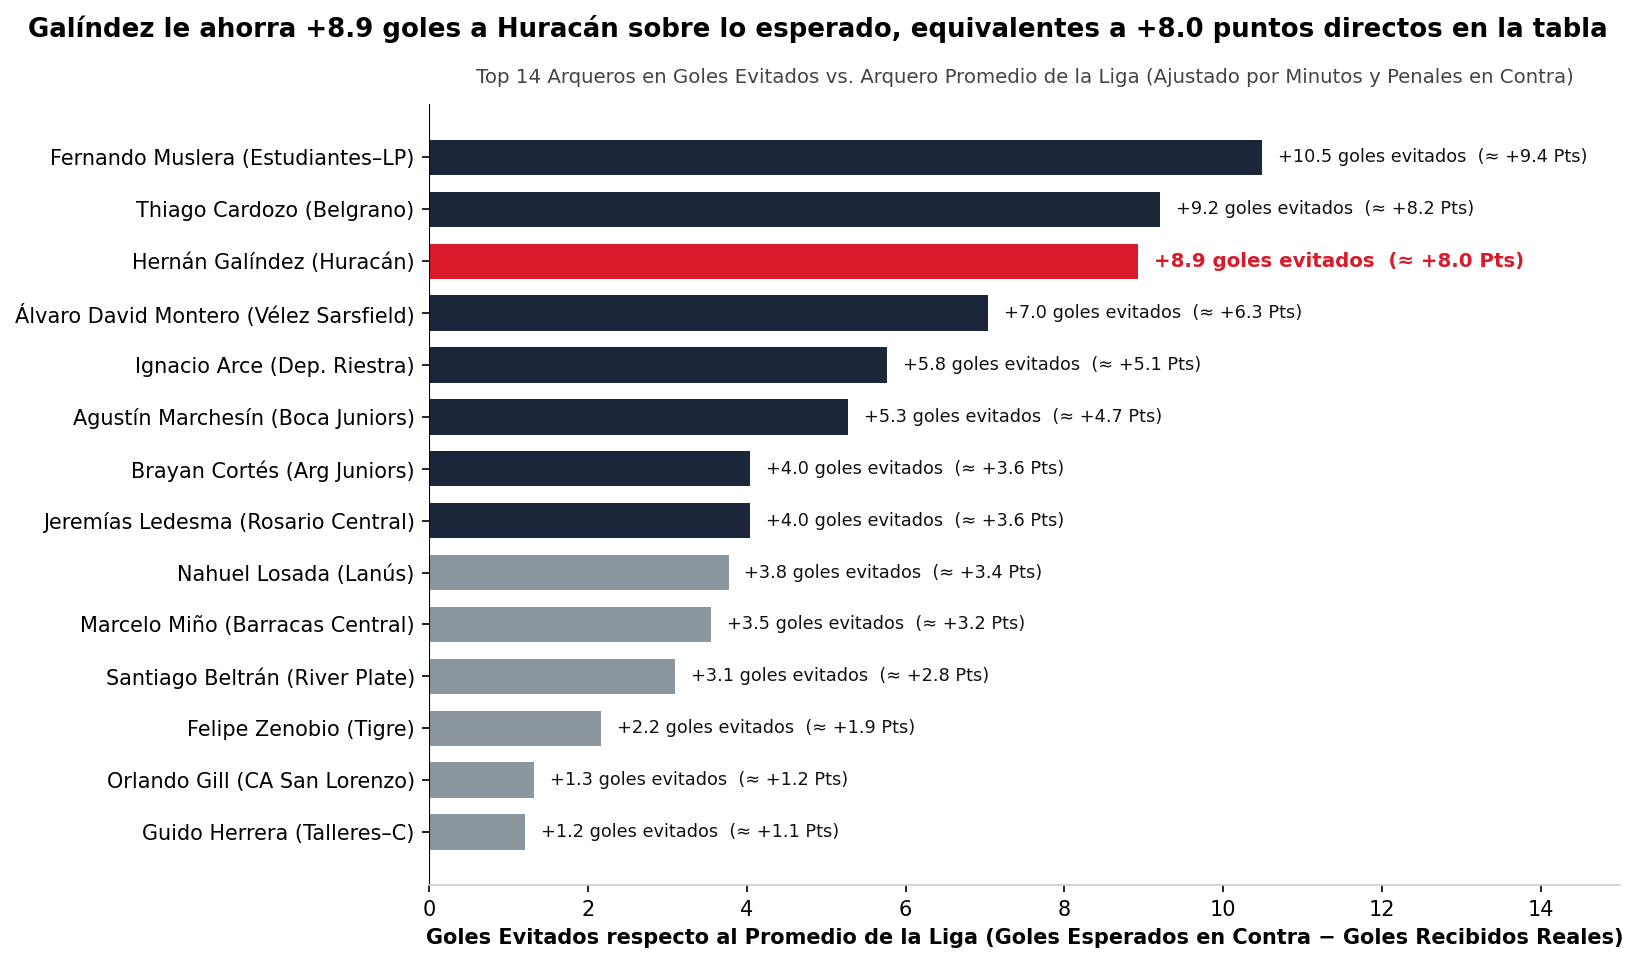

In [10]:
# ==============================================================================
# 8. Visualización 2: Top arqueros en Goles Evitados y Puntos Aportados (WPA)
# ==============================================================================
top_evitados = df_master.sort_values('Goles_Evitados_vs_Benchmark', ascending=True).tail(14)

fig, ax = plt.subplots(figsize=(11, 6.5), dpi=150)
colores_barras = [COLOR_HURACAN if sq == 'Huracán' else COLOR_OSCURO if val > 4 else COLOR_GRIS
                  for sq, val in zip(top_evitados['Squad'], top_evitados['Goles_Evitados_vs_Benchmark'])]

etiquetas_y = top_evitados['GK_Titular'] + ' (' + top_evitados['Squad'] + ')'
bars = ax.barh(etiquetas_y, top_evitados['Goles_Evitados_vs_Benchmark'], color=colores_barras, height=0.68)
ax.axvline(0, color='black', linewidth=1)

for bar, (_, row) in zip(bars, top_evitados.iterrows()):
    val = row['Goles_Evitados_vs_Benchmark']
    pts = row['Puntos_Aportados_Arco']
    es_hur = row['Squad'] == 'Huracán'
    ax.text(val + 0.2, bar.get_y() + bar.get_height()/2,
            f"+{val:.1f} goles evitados  (≈ +{pts:.1f} Pts)",
            va='center', ha='left', fontsize=8.5 if not es_hur else 9.5,
            fontweight='bold' if es_hur else 'normal',
            color=COLOR_HURACAN if es_hur else '#111111')

plt.suptitle('Galíndez le ahorra +8.9 goles a Huracán sobre lo esperado, equivalentes a +8.0 puntos directos en la tabla',
             fontsize=12.5, fontweight='bold', y=0.98)
ax.set_title('Top 14 Arqueros en Goles Evitados vs. Arquero Promedio de la Liga (Ajustado por Minutos y Penales en Contra)',
             fontsize=9.5, color='#444444', pad=10)
ax.set_xlabel('Goles Evitados respecto al Promedio de la Liga (Goles Esperados en Contra − Goles Recibidos Reales)', fontweight='bold')
ax.set_xlim(0, 15.0)
sns.despine(left=True)
plt.tight_layout()
os.makedirs(OUTPUT_PATH, exist_ok=True)
plt.savefig(os.path.join(OUTPUT_PATH, '02_galindez_goles_evitados_wpa.png'), dpi=150)
plt.show()

---
## 9. Gráfico 3: Auditoría de Edad vs. Disponibilidad Física

* **En simple:** Evaluamos si sus 39.5 años implican menor presencia en cancha o sanciones disciplinarias frente al resto de los arqueros del torneo.
* **Bajo el capó:** Cruzamos la edad decimal exacta (`GK_Age`) con el porcentaje de minutos jugados sobre el total del equipo (`GK_Share_Pct`), incorporando una tercera dimensión mediante el mapa de color divergente (`RdYlGn`) según los *Goles Evitados*.

#### 🐦 Tuit 5 (4/5 — Gráfico 3):
> **4/5 — Gráfico 3: Derribando el mito de la edad (39.5 años)** ⏳🏃‍♂️
>
> En cualquier Comisión Directiva surge la duda: *"¿Y si a los 40 años empieza a perder continuidad?"*
>
> 💡 **El método:** Transformé la edad de cada arquero a formato decimal exacto (años + días) y la crucé contra su **% de disponibilidad física en cancha**, coloreando cada punto según los Goles Evitados (Verde = Élite).
>
> 📍 **El hallazgo:** Con 39.5 años, Galíndez jugó el **92.6% de los minutos totales** (superando la media de la Liga), registró **0 tarjetas amarillas** y mantuvo un nivel de élite.
>
> *(Adjuntar imagen: `03_galindez_auditoria_edad_disponibilidad.png`)*

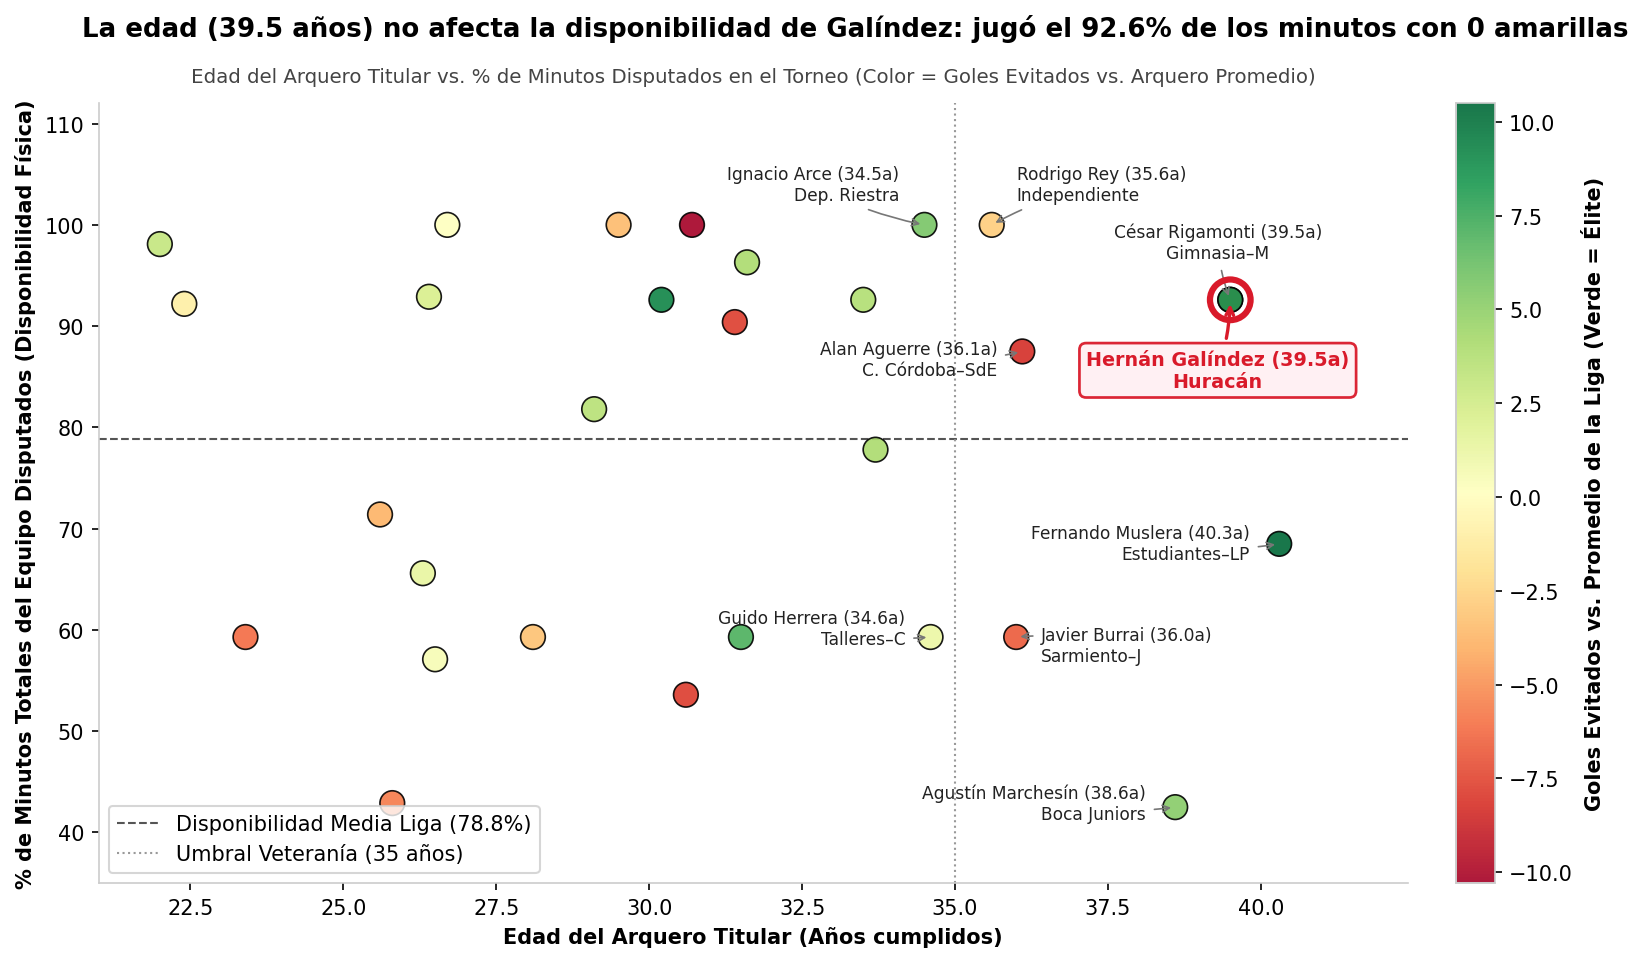

In [11]:
# ==============================================================================
# 9. Visualización 3: Edad vs. Disponibilidad Física y Rendimiento
# ==============================================================================
fig, ax = plt.subplots(figsize=(11.5, 6.5), dpi=150)

sc = ax.scatter(df_master['GK_Age'], df_master['GK_Share_Pct'],
                c=df_master['Goles_Evitados_vs_Benchmark'], cmap='RdYlGn',
                s=140, edgecolors='black', linewidth=0.8, alpha=0.9, zorder=4)
ax.scatter(huracan['GK_Age'], huracan['GK_Share_Pct'],
           color='none', edgecolors=COLOR_HURACAN, s=380, linewidth=3, zorder=7)

ax.axhline(df_master['GK_Share_Pct'].mean(), color='#555555', linestyle='--', linewidth=1,
           label=f"Disponibilidad Media Liga ({df_master['GK_Share_Pct'].mean():.1f}%)")
ax.axvline(35.0, color='#999999', linestyle=':', linewidth=1, label='Umbral Veteranía (35 años)')

posiciones_etiquetas = {
    'Dep. Riestra':    (-12,  10, 'right',  'bottom'),
    'Independiente':   ( 12,  10, 'left',   'bottom'),
    'C. Córdoba–SdE':  (-12,  -4, 'right',  'center'),
    'Gimnasia–M':      ( -6,  18, 'center', 'bottom'),
    'Huracán':         ( -6, -24, 'center', 'top'),
    'Estudiantes–LP':  (-14,   0, 'right',  'center'),
    'Talleres–C':      (-12,   4, 'right',  'center'),
    'Sarmiento–J':     ( 12,  -4, 'left',   'center'),
    'Boca Juniors':    (-14,   2, 'right',  'center'),
}

for _, row in df_master.iterrows():
    if row['GK_Age'] >= 34.5 or row['Squad'] in ['Huracán', 'Estudiantes–LP', 'Boca Juniors', 'Independiente']:
        es_hur = row['Squad'] == 'Huracán'
        dx, dy, ha_align, va_align = posiciones_etiquetas.get(
            row['Squad'],
            (-10 if row['GK_Age'] > 38 else 8, 6, 'right' if row['GK_Age'] > 38 else 'left', 'center')
        )

        bbox_style = dict(boxstyle='round,pad=0.35', facecolor='#FFF0F3', edgecolor=COLOR_HURACAN, lw=1.3, alpha=0.95) if es_hur else None
        arrow_style = dict(arrowstyle='->', color=COLOR_HURACAN if es_hur else '#777777', lw=1.6 if es_hur else 0.8, connectionstyle='arc3,rad=0.08')

        ax.annotate(
            f"{row['GK_Titular']} ({row['GK_Age']}a)\n{row['Squad']}",
            xy=(row['GK_Age'], row['GK_Share_Pct']),
            xytext=(dx, dy), textcoords='offset points',
            ha=ha_align, va=va_align,
            fontsize=9.2 if es_hur else 8.2,
            fontweight='bold' if es_hur else 'normal',
            color=COLOR_HURACAN if es_hur else '#222222',
            bbox=bbox_style,
            arrowprops=arrow_style,
            zorder=8 if es_hur else 6
        )

cbar = plt.colorbar(sc, ax=ax, pad=0.03)
cbar.set_label('Goles Evitados vs. Promedio de la Liga (Verde = Élite)', fontweight='bold')

plt.suptitle('La edad (39.5 años) no afecta la disponibilidad de Galíndez: jugó el 92.6% de los minutos con 0 amarillas',
             fontsize=12.5, fontweight='bold', y=0.98)
ax.set_title('Edad del Arquero Titular vs. % de Minutos Disputados en el Torneo (Color = Goles Evitados vs. Arquero Promedio)',
             fontsize=9.5, color='#444444', pad=10)
ax.set_xlabel('Edad del Arquero Titular (Años cumplidos)', fontweight='bold')
ax.set_ylabel('% de Minutos Totales del Equipo Disputados (Disponibilidad Física)', fontweight='bold')
ax.set_xlim(21.0, 42.4)
ax.set_ylim(35, 112)
ax.legend(loc='lower left', frameon=True)
sns.despine()
plt.tight_layout()
os.makedirs(OUTPUT_PATH, exist_ok=True)
plt.savefig(os.path.join(OUTPUT_PATH, '03_galindez_auditoria_edad_disponibilidad.png'), dpi=150)
plt.show()

---
## 10. Gráfico 4: Simulación Contrafactual para la Comisión Directiva

* **En simple:** Proyectamos cuántos puntos y qué posición tendría Huracán en la tabla si en lugar de Galíndez hubiera atajado un arquero promedio de la Liga Profesional.
* **Bajo el capó:** Utilizando el modelo regresivo OLS entre Diferencia de Gol y Puntos ($r = 0.927, p < 10^{-12}$), restamos los *Puntos Aportados* por Galíndez ($\text{Pts}_{\text{Contrafactual}} = \text{Pts}_{\text{Real}} - \text{WPA} = 38 - 8 = 30\text{ pts}$) y recalculamos su ubicación en la clasificación general (del puesto 13° al 23°).

#### 🐦 Tuit 6 (5/5 — Gráfico 4):
> **5/5 — Gráfico 4: La Simulación Contrafactual (¿Cómo estaría Huracán sin Galíndez?)** 🔮📉
>
> ¿Cómo se cuantifica el riesgo de no renovarle? Simulando una tabla contrafactual.
>
> 💡 **El método predictivo:** Entrené una **Regresión Lineal** entre la Diferencia de Gol y los Puntos de los 30 clubes ($r = 0.927$): en la Liga Argentina, cada gol neto equivale a **~0.90 puntos**.
>
> Si reemplazamos a Galíndez por un arquero promedio de la Liga (perdiendo sus +8.9 goles salvados):
> 🔴 **Con Galíndez (Realidad):** 38 pts — **Puesto 13°** (Zona competitiva)
> ⚪ **Sin Galíndez (Simulación):** 30 pts — **Puesto 23°** (Zona baja)
>
> Prescindir de su rendimiento equivale a arriesgar **8 puntos y 10 puestos en la tabla**.
>
> *(Adjuntar imagen: `04_galindez_simulacion_contrafactual_puntos.png`)*

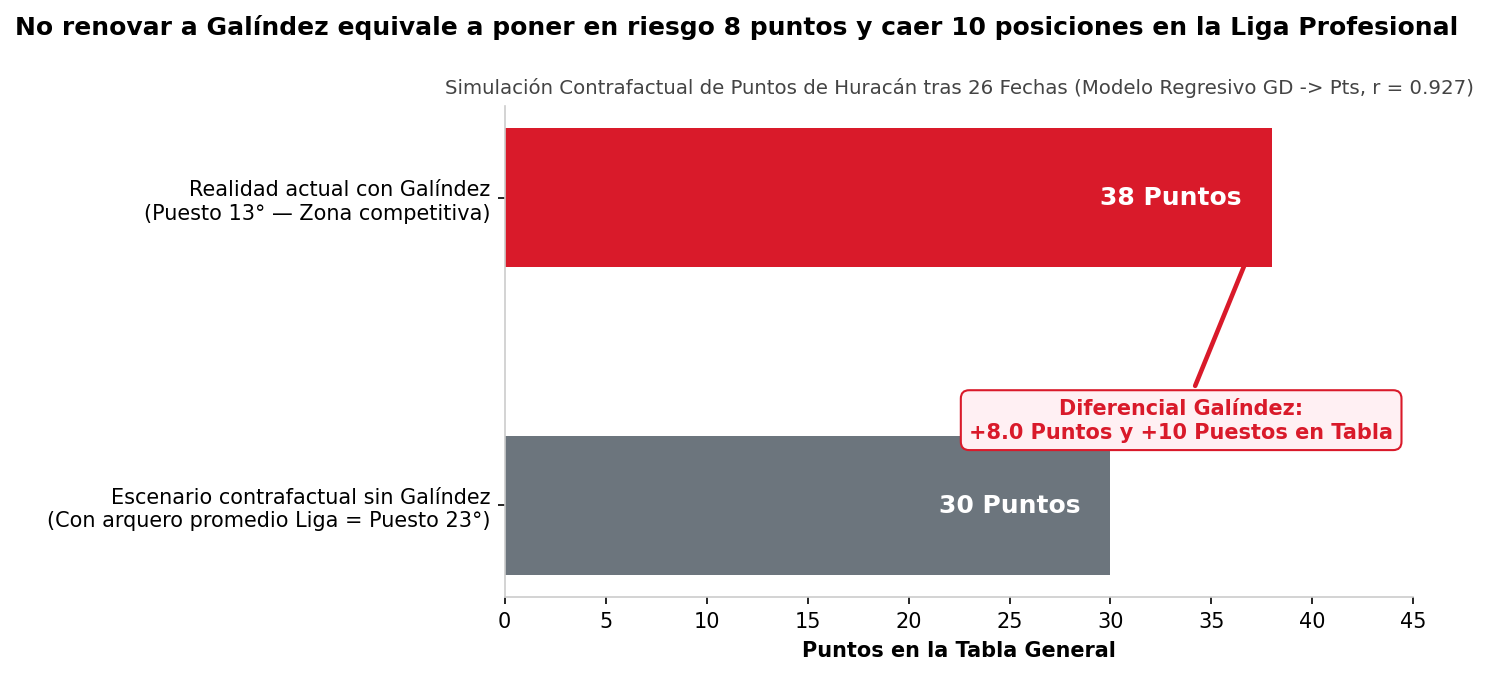

In [12]:
# ==============================================================================
# 10. Visualización 4: Simulación contrafactual de puntos en la tabla
# ==============================================================================
pts_actual = huracan['Pts']  # 38.0
pts_sin_galindez = round(pts_actual - huracan['Puntos_Aportados_Arco'], 1)  # 30.0

fig, ax = plt.subplots(figsize=(9.5, 4.5), dpi=150)
categorias = [
    'Escenario contrafactual sin Galíndez\n(Con arquero promedio Liga = Puesto 23°)',
    'Realidad actual con Galíndez\n(Puesto 13° — Zona competitiva)'
]
valores = [pts_sin_galindez, pts_actual]
colores = ['#6C757D', COLOR_HURACAN]

bars = ax.barh(categorias, valores, color=colores, height=0.45)
for bar, val in zip(bars, valores):
    ax.text(val - 1.5, bar.get_y() + bar.get_height()/2, f"{val:.0f} Puntos",
            va='center', ha='right', color='white', fontweight='bold', fontsize=12)

ax.annotate("Diferencial Galíndez:\n+8.0 Puntos y +10 Puestos en Tabla",
            xy=(pts_actual, 1), xytext=(33.5, 0.22),
            arrowprops=dict(arrowstyle="->", color=COLOR_HURACAN, lw=2.2),
            fontsize=10, fontweight='bold', color=COLOR_HURACAN, ha='center',
            bbox=dict(boxstyle='round,pad=0.4', facecolor='#FFF0F3', edgecolor=COLOR_HURACAN))

plt.suptitle('No renovar a Galíndez equivale a poner en riesgo 8 puntos y caer 10 posiciones en la Liga Profesional',
             fontsize=12, fontweight='bold', y=0.99)
ax.set_title('Simulación Contrafactual de Puntos de Huracán tras 26 Fechas (Modelo Regresivo GD -> Pts, r = 0.927)',
             fontsize=9.5, color='#444444')
ax.set_xlabel('Puntos en la Tabla General', fontweight='bold')
ax.set_xlim(0, 45)
sns.despine()
plt.tight_layout()
os.makedirs(OUTPUT_PATH, exist_ok=True)
plt.savefig(os.path.join(OUTPUT_PATH, '04_galindez_simulacion_contrafactual_puntos.png'), dpi=150)
plt.show()

---
## 11. Conclusiones Ejecutivas y Cierre del Hilo

1. **Rendimiento de Élite ($Z = +1.17$ SD en Goles Evitados):** Es el 2° arquero que más goles ahorra en la Liga Profesional (+8.9 goles respecto al promedio).
2. **Sostén en contextos adversos:** Sostiene la 3° valla más sólida en jugada abierta pese a actuar detrás de la defensa más sancionada del torneo (6 penales y 6 expulsiones).
3. **Plena vigencia física:** Con 39.5 años disputó el 92.6% de los minutos posibles con 0 tarjetas amarillas.
4. **Retorno deportivo directo:** Su aporte equivale a **+8.0 puntos y +10 posiciones** en la tabla general.

> **Recomendación Estratégica:** Avanzar con la renovación contractual de Hernán Galíndez por 1 temporada con cláusula de extensión automática sujeta a disponibilidad física ($\ge 60\%$ de los minutos).

#### 🐦 Tuit 7: Cierre y Call to Action (Networking)
> **Conclusión de la Auditoría para la Secretaría Técnica:** 📋✅
>
> Salir al mercado de pases a buscar un reemplazo que garantice +8.9 Goles Evitados y +8 puntos por torneo es financieramente más costoso y deportivamente más riesgoso que renovar su contrato.
>
> 💡 **Recomendación basada en datos:** Renovación por 1 año con cláusula de extensión automática por objetivos de disponibilidad ($\ge 60\%$ de los minutos).
>
> 💻 Todo el código en Python, la limpieza de datos de FBref y los tests estadísticos están documentados en mi repositorio.
>
> ¿Qué otro jugador o plantel del fútbol argentino les gustaría que audite con este modelo? Los leo 👇⚽📊